<div>
    <img src="UoL.jpg" width="284" style="float: left;">
<img src="SIM.jpg" width="100" style="float: right;">
</div>

Week 5-3.10 Worked example: adding structure to data by making a word cloud<br>
Week 5-3.12 Stemming, lemmatization and word meaning


<center>
  <a href="Lesson.2.3.CountingWords.ipynb">Previous Page</a> | <a href="./">Content Page</a> </center>
</center>

# Word Cloud & Stemmer

The Natural Language Toolkit (NLTK) is a library for working with human language data.
It provides easy-to-use interfaces for tasks such as `tokenization, stemming, tagging, parsing, and semantic reasoning.`

<a href='Nltk 01 - Tokenise_3.2_Revision Lab1.ipynb'><H1/>Nltk 01 - Tokenise_3.2_Revision Lab1</a>

In [1]:
import pandas as pd
import nltk

In [4]:
nltk.download('webtext')
nltk.download('gutenberg')

[nltk_data] Downloading package webtext to
[nltk_data]     C:\Users\Python\AppData\Roaming\nltk_data...
[nltk_data]   Package webtext is already up-to-date!
[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\Python\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\gutenberg.zip.


True

The webtext corpus is a part of NLTK and contains text from online sources.
It can be used for various natural language processing (NLP) tasks and text analysis

In [5]:
from nltk.corpus import webtext

In [6]:
from nltk.corpus import webtext

# List the file IDs in the webtext corpus
file_ids = webtext.fileids()
print(file_ids)

['firefox.txt', 'grail.txt', 'overheard.txt', 'pirates.txt', 'singles.txt', 'wine.txt']


```firefox.txt: Likely contains text related to the Firefox web browser.
grail.txt: Possibly includes text from the Monty Python and the Holy Grail script.
overheard.txt: Contains snippets of conversations overheard in New York.
pirates.txt: Likely includes text from the Pirates of the Caribbean script.
singles.txt: Could contain text related to dating or singles ads.
wine.txt: Likely includes text about wine reviews or discussions.```


In [7]:
pirate_text=webtext.raw('pirates.txt')

In [8]:
pirate_text

'PIRATES OF THE CARRIBEAN: DEAD MAN\'S CHEST, by Ted Elliott & Terry Rossio\n[view looking straight down at rolling swells, sound of wind and thunder, then a low heartbeat]\nScene: PORT ROYAL\n[teacups on a table in the rain]\n[sheet music on music stands in the rain]\n[bouquet of white orchids, Elizabeth sitting in the rain holding the bouquet]\n[men rowing, men on horseback, to the sound of thunder]\n[EITC logo on flag blowing in the wind]\n[many rowboats are entering the harbor]\n[Elizabeth sitting alone, at a distance]\n[marines running, kick a door in] \n[a mule is seen on the left in the barn where the marines enter]\n[Liz looking over her shoulder]\n[Elizabeth drops her bouquet]\n[Will is in manacles, being escorted by red coats]\nELIZABETH SWANN: Will...!\n[Elizabeth runs to Will]\nELIZABETH SWANN: Why is this happening? \nWILL TURNER: I don\'t know. You look beautiful.\nELIZABETH SWANN: I think it\'s bad luck for the groom to see the bride before the wedding.\n[marines cross t

In [9]:
from nltk.probability import FreqDist
from wordcloud import WordCloud  # Is not installed.
import matplotlib.pyplot as plt

<br><br><br><br><br><br>
- The below line downloads the "punkt" tokenizer models.
- The "punkt" tokenizer is a pre-trained model that can be used for tokenizing text into sentences and words.
- It's useful for tasks like text processing, where you need to split text into its constituent sentences and words.

In [ ]:
nltk.download('punkt')

sent_tokenize and word_tokenize are NLTK functions.
- sent_tokenize is used to split text into sentences.
- word_tokenize is used to split text into words or tokens

In [10]:
from nltk import sent_tokenize, word_tokenize

<br><br><br><br><br>
The below line downloads the WordNet lexical database.
- WordNet is a large lexical database of English, organized by semantic relationships.
- It's commonly used for various natural language processing (NLP) tasks, including word sense disambiguation, **synonym and antonym** retrieval, and semantic analysis.

In [11]:

nltk.download('wordnet')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Python\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [12]:
myWords =[]
#data = pd.read_csv('HanselNGretel.txt')
f = open('HanselNGretel.txt', 'r')
data=f.read()

#lines = data.split('.') #Split data with .
#number_of_rows=len(lines)
#print(number_of_rows)

In [14]:
data[0:200]

'Hard by a great forest dwelt a poor wood-cutter with his wife and his two children. The boy was called Hansel and the girl Gretel. He had little to bite and to break, and once when great dearth fell o'

#### Comparing Split with Tokenize

In [15]:
myWords=data.split(" ")


In [16]:
Mywords=nltk.word_tokenize(data)

In [21]:
myWords== Mywords

False

In [17]:
Mywords

['Hard',
 'by',
 'a',
 'great',
 'forest',
 'dwelt',
 'a',
 'poor',
 'wood-cutter',
 'with',
 'his',
 'wife',
 'and',
 'his',
 'two',
 'children',
 '.',
 'The',
 'boy',
 'was',
 'called',
 'Hansel',
 'and',
 'the',
 'girl',
 'Gretel',
 '.',
 'He',
 'had',
 'little',
 'to',
 'bite',
 'and',
 'to',
 'break',
 ',',
 'and',
 'once',
 'when',
 'great',
 'dearth',
 'fell',
 'on',
 'the',
 'land',
 ',',
 'he',
 'could',
 'no',
 'longer',
 'procure',
 'even',
 'daily',
 'bread',
 '.',
 'Now',
 'when',
 'he',
 'thought',
 'over',
 'this',
 'by',
 'night',
 'in',
 'his',
 'bed',
 ',',
 'and',
 'tossed',
 'about',
 'in',
 'his',
 'anxiety',
 ',',
 'he',
 'groaned',
 'and',
 'said',
 'to',
 'his',
 'wife',
 ':',
 'â€˜What',
 'is',
 'to',
 'become',
 'of',
 'us',
 '?',
 'How',
 'are',
 'we',
 'to',
 'feed',
 'our',
 'poor',
 'children',
 ',',
 'when',
 'we',
 'no',
 'longer',
 'have',
 'anything',
 'even',
 'for',
 'ourselves',
 '?',
 'â€™',
 'â€˜Iâ€™ll',
 'tell',
 'you',
 'what',
 ',',
 'husband',

In [19]:
Mysentences=nltk.sent_tokenize(data)

In [20]:
Mysentences

['Hard by a great forest dwelt a poor wood-cutter with his wife and his two children.',
 'The boy was called Hansel and the girl Gretel.',
 'He had little to bite and to break, and once when great dearth fell on the land, he could no longer procure even daily bread.',
 'Now when he thought over this by night in his bed, and tossed about in his anxiety, he groaned and said to his wife: â€˜What is to become of us?',
 'How are we to feed our poor children, when we no longer have anything even for ourselves?â€™ â€˜Iâ€™ll tell you what, husband,â€™ answered the woman, â€˜early tomorrow morning we will take the children out into the forest to where it is the thickest; there we will light a fire for them, and give each of them one more piece of bread, and then we will go to our work and leave them alone.',
 'They will not find the way home again, and we shall be rid of them.â€™ â€˜No, wife,â€™ said the man, â€˜I will not do that; how can I bear to leave my children alone in the forest?--the w

#### Counting Word

In [22]:
data_analysis=nltk.FreqDist(myWords)

In [23]:
data_analysis

FreqDist({'the': 159, 'and': 154, 'to': 72, 'a': 43, 'they': 42, 'of': 41, 'had': 40, 'was': 33, 'in': 32, 'little': 30, ...})

#### Finding Word is is greater than 5 characters e.g., "the" is only 3, "little" is 5  (3 APPROACHES)

FIRST (list comprehension)

In [28]:
filter_words = dict([m, n] for m, n in data_analysis.items() if len (m) > 5)

SECOND (for loop)

In [26]:
filt_word={}
for Wrd, Cnt in data_analysis.items():
    #print(Wrd,Cnt)
    if len(Wrd) > 5:
        filt_word[Wrd]=Cnt


In [29]:
filt_word== filter_words

True

#### Using dict

THIRD (combine dictionary)

In [30]:
my_dict = dict([(1,'apple'), (2,'ball')])
my_dict1 = {1:'apple', 2:'ball'}
params = {'a': 1, 'b': 2}
new_params = {**params, **{'c': 3}}

Creating a new dictionary *new_params* by merging the contents of two dictionaries, *params and {'c': 3}*.

In [32]:
new_params

{'a': 1, 'b': 2, 'c': 3}

In [33]:
my_dict


{1: 'apple', 2: 'ball'}

In [35]:
my_dict==my_dict1

True

In [36]:
new_params = {**new_params, **my_dict}

In [37]:
new_params

{'a': 1, 'b': 2, 'c': 3, 1: 'apple', 2: 'ball'}

In [38]:
filt_word1={}
for Wrd, Cnt in data_analysis.items():
    #print(Wrd,Cnt)
    if len(Wrd) > 5:
        filt_word1 = {**filt_word1, **{Wrd:Cnt}}


In [40]:
filter_words == filt_word == filt_word1 

True

#### Generating WordCloud Object

In [41]:
wcloud=WordCloud().generate_from_frequencies(filter_words)

In [42]:
wcloud.background_color='black'

- plt.axis("off") is used to turn off the axis, which means the axis won't be displayed, including ticks and labels.

- plt.axis **([-1.5, 200, 100, -2.5])** manually sets the limits for the x and y axes. 
   - The first two values [xmin, xmax] set the limits for the x-axis, and 
   - the last two values [ymin, ymax] set the limits for the y-axis.

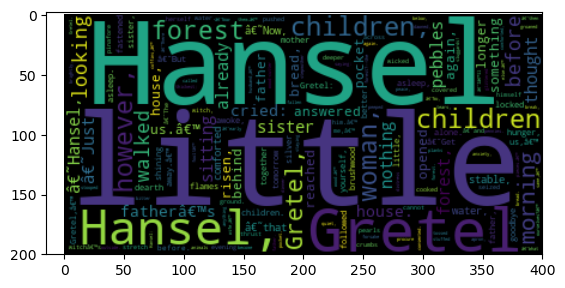

In [43]:
plt.imshow(wcloud, interpolation='bilinear')
#plt.axis("off")
plt.axis("on")
plt.axis([-15, 400, 200, -2.5])
plt.show()

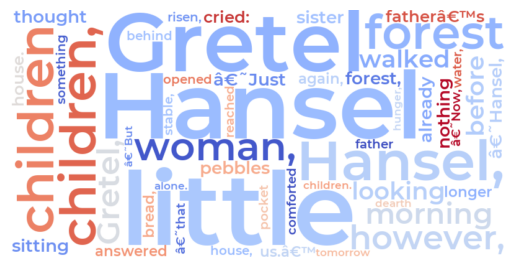

In [104]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Create a WordCloud object with custom settings
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='coolwarm',
    font_path='Montserrat.ttf',  # Specify a custom font file
    max_words=50,  # Limit the number of words displayed
    relative_scaling=0.5,  # Adjust word size scaling
    contour_width=2,  # Add a contour around the words
    contour_color='black',  # Color of the contour
)

# Generate the word cloud from word frequencies
wordcloud.generate_from_frequencies(filter_words)

# Display the word cloud using 'bilinear' interpolation for smooth appearance
plt.imshow(wordcloud, interpolation="bilinear")

# Turn off axis labels and ticks
plt.axis("off")

# Show the word cloud
plt.show()

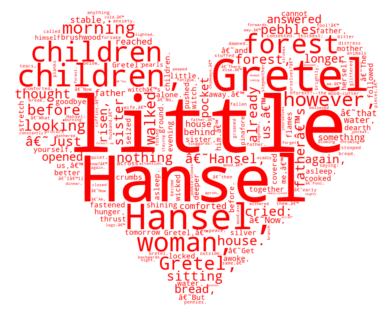

In [45]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Your text data (replace this with your own text)

# Load a heart-shaped mask
heart_mask = np.array(Image.open("heart1.png"))

# Create a WordCloud with a custom mask

wordcloud = WordCloud(
   width=800,                   # Set the width of the Word Cloud image to 800 pixels.
   height=400,                  # Set the height of the Word Cloud image to 400 pixels.
   background_color="white",    # Set the background color of the Word Cloud to white.
   mask=heart_mask,             # Use a custom shape (mask) for the Word Cloud, defined as 'heart_mask'.
   #colormap="coolwarm",         # Set the colormap for coloring the words in the Word Cloud to "coolwarm".
   #colormap="Reds",
   color_func=lambda *args, **kwargs: "hsl(0, 100%, 50%)"  # Define a custom color function for the words in the Word Cloud.
).generate_from_frequencies(filter_words)


# Create a figure for the plot
plt.figure(figsize=(8, 4))

# Display the word cloud using 'bilinear' interpolation for smooth appearance
plt.imshow(wordcloud, interpolation="bilinear")

# Turn off axis labels and ticks
plt.axis("off")

# Show the word cloud
plt.show()


color_func: This is a function that allows you to define a custom coloring function for the words in the Word Cloud. In this case, you are using a lambda function that returns a specific HSL (Hue, Saturation, Lightness) color value. "hsl(0, 100%, 50%)" corresponds to a fully saturated red color.

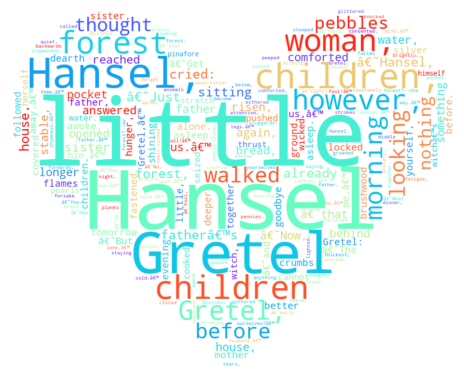

In [46]:
wordcloud = WordCloud(
    width=1800,               # Width of the word cloud canvas
    height=1400,              # Height of the word cloud canvas
    background_color="white", # Background color
    colormap="rainbow",
#    background_color="lightblue", 
 #   colormap="viridis",
    mask=heart_mask          # Custom heart-shaped mask
).generate_from_frequencies(filter_words)

# Display the word cloud using 'bilinear' interpolation for smooth appearance
plt.imshow(wordcloud, interpolation="bilinear")

# Turn off axis labels and ticks
plt.axis("off")

# Show the word cloud
plt.show()

### Word Cloud for Comparison

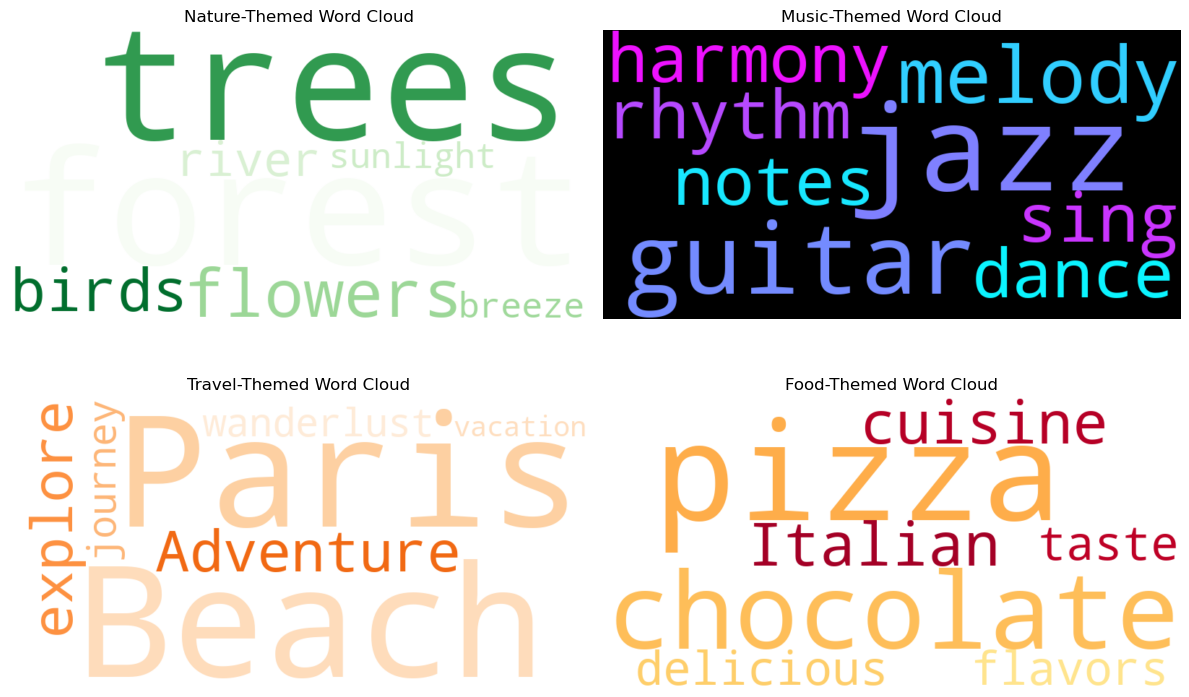

In [47]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Example 1: Nature-Themed Word Cloud
nature_text = "forest trees flowers birds river sunlight breeze"
wordcloud1 = WordCloud(width=800, height=400, background_color='white', colormap='Greens', contour_color='brown').generate(nature_text)

# Example 2: Music-Themed Word Cloud
music_text = "jazz guitar melody harmony notes rhythm dance sing"
wordcloud2 = WordCloud(width=800, height=400, background_color='black', colormap='cool', contour_color='white').generate(music_text)

# Example 3: Travel-Themed Word Cloud
travel_text = "Paris Beach Adventure explore wanderlust journey vacation"
wordcloud3 = WordCloud(width=800, height=400, background_color='white', colormap='Oranges', contour_color='blue').generate(travel_text)

# Example 4: Food-Themed Word Cloud
food_text = "pizza chocolate Italian cuisine delicious flavors taste"
wordcloud4 = WordCloud(width=800, height=400, background_color='white', colormap='YlOrRd', contour_color='darkred').generate(food_text)

# Display the Word Clouds
plt.figure(figsize=(12, 8))
# This line creates a new figure with a specified size of 12 inches by 8 inches.


plt.subplot(221) #plt.subplot(221): This creates a subplot in a 2x2 grid (2 rows, 2 columns) 
# and selects the first subplot (top-left).
plt.imshow(wordcloud1, interpolation='bilinear')
plt.title("Nature-Themed Word Cloud")
plt.axis("off")

plt.subplot(222) # plt.subplot(222): Selects the second subplot (top-right) in the 2x2 grid.
plt.imshow(wordcloud2, interpolation='bilinear')
plt.title("Music-Themed Word Cloud")
plt.axis("off")

plt.subplot(223) # Selects the third subplot (bottom-left) in the 2x2 grid.
plt.imshow(wordcloud3, interpolation='bilinear')
plt.title("Travel-Themed Word Cloud")
plt.axis("off")

plt.subplot(224)# Selects the fourth subplot (bottom-right) in the 2x2 grid.
plt.imshow(wordcloud4, interpolation='bilinear')
plt.title("Food-Themed Word Cloud")
plt.axis("off")

plt.tight_layout() # This adjusts the spacing between subplots to prevent overlap and ensure a neat layout
plt.show()


### Write a Wordcloud showing how happy we were during Valentine day last year

In [8]:
ourVal="Valentine's Day last year was a day filled with joy, love, \
and cherished memories. We celebrated our connection, and the happiness \
we shared was immeasurable. The smiles, the laughter, and the warmth of \
our hearts coming together made it a day to remember. Our love bloomed \
like a beautiful bouquet of roses, and the memories we created on that \
special day continue to brighten our lives. It's a reminder that love \
grows stronger with time, and the happiness we felt on that Valentine's Day \
still warms our hearts today"

In [9]:
import nltk
from nltk import word_tokenize
Myval=nltk.word_tokenize(ourVal)

In [15]:
from nltk import *

In [11]:
import nltk

In [ ]:
nltk.sent_tokenize

In [12]:
nltk.sent_tokenize(ourVal)

["Valentine's Day last year was a day filled with joy, love, and cherished memories.",
 'We celebrated our connection, and the happiness we shared was immeasurable.',
 'The smiles, the laughter, and the warmth of our hearts coming together made it a day to remember.',
 'Our love bloomed like a beautiful bouquet of roses, and the memories we created on that special day continue to brighten our lives.',
 "It's a reminder that love grows stronger with time, and the happiness we felt on that Valentine's Day still warms our hearts today"]

In [13]:
# Remove non alpha
ourVal_clean = [i for i in Myval if i.isalpha()]

In [14]:
from nltk.probability import FreqDist

countVal=nltk.FreqDist(ourVal_clean)

In [126]:
countVal

FreqDist({'and': 5, 'the': 5, 'a': 4, 'our': 4, 'day': 3, 'love': 3, 'we': 3, 'that': 3, 'Valentine': 2, 'Day': 2, ...})

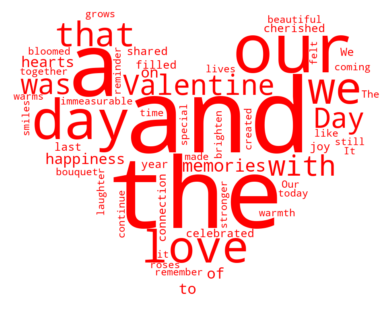

In [139]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Your text data (replace this with your own text)

# Load a heart-shaped mask
heart_mask = np.array(Image.open("heart1.png"))

# Create a WordCloud with a custom mask

wordcloud = WordCloud(
   width=800,                   # Set the width of the Word Cloud image to 800 pixels.
   height=400,                  # Set the height of the Word Cloud image to 400 pixels.
   background_color="white",    # Set the background color of the Word Cloud to white.
   mask=heart_mask,             # Use a custom shape (mask) for the Word Cloud, defined as 'heart_mask'.
   colormap="coolwarm",         # Set the colormap for coloring the words in the Word Cloud to "coolwarm".
   color_func=lambda *args, **kwargs: "hsl(0, 100%, 50%)"  # Define a custom color function for the words in the Word Cloud.
).generate_from_frequencies(countVal)


# Create a figure for the plot
plt.figure(figsize=(8, 4))

# Display the word cloud using 'bilinear' interpolation for smooth appearance
plt.imshow(wordcloud, interpolation="bilinear")

# Turn off axis labels and ticks
plt.axis("off")

# Show the word cloud
plt.show()


In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Your text data (replace this with your own text)

# Load a heart-shaped mask
heart_mask = np.array(Image.open("heart1.png"))

# Create a WordCloud with a custom mask

wordcloud = WordCloud(
   width=800,                   # Set the width of the Word Cloud image to 800 pixels.
   height=400,                  # Set the height of the Word Cloud image to 400 pixels.
   background_color="white",    # Set the background color of the Word Cloud to white.
   mask=heart_mask,             # Use a custom shape (mask) for the Word Cloud, defined as 'heart_mask'.
   colormap="coolwarm",         # Set the colormap for coloring the words in the Word Cloud to "coolwarm".
   color_func=lambda *args, **kwargs: "hsl(0, 100%, 50%)"  # Define a custom color function for the words in the Word Cloud.
).generate_from_frequencies(___________)


# Create a figure for the plot
plt.figure(figsize=(8, 4))

# Display the word cloud using 'bilinear' interpolation for smooth appearance
plt.imshow(wordcloud, interpolation="bilinear")

# Turn off axis labels and ticks
plt.axis("off")

# Show the word cloud
plt.show()


# Stemmer

<a href='Nltk 04 - StemmingRevision lab 2 - Finding root forms of words_3.2_Revision Lab2.ipynb'><H1/>Nltk 04 - StemmingRevision lab 2 - Finding root forms of words_3.2_Revision Lab2</a>

The PorterStemmer is a popular stemming algorithm developed by Martin Porter. It's used to reduce words to their base or root form by applying a set of heuristic rules. For example, it can convert words like "running," "ran," and "runner" to their common root "run." It's a simple and fast algorithm, but it may not always produce dictionary words.

In [140]:
from nltk.stem import PorterStemmer


The WordNetLemmatizer is a lemmatization tool provided by NLTK. Lemmatization aims to transform words into their base or dictionary forms. Unlike stemming, lemmatization ensures that the output is a valid word in the language. It uses the WordNet lexical database to perform lemmatization, which is a comprehensive lexical database of English.

In [141]:
from nltk.stem import WordNetLemmatizer


The LancasterStemmer is another stemming algorithm available in NLTK. It is based on the Lancaster stemming algorithm, which is more aggressive than the Porter Stemmer. It may produce shorter stems but at the cost of potentially losing some meaning. For example, it might convert "unhappiness" to "unhappy" and "running" to "run."

You can use these tools to preprocess text data in NLP tasks to reduce the complexity of the text while maintaining some level of semantic meaning. The choice of which tool to use depends on your specific NLP task and `the trade-off between stemming (which can be more aggressive) and lemmatization (which tends to be more precise but computationally expensive).`

In [142]:
from nltk.stem import LancasterStemmer

In [143]:
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.stem import LancasterStemmer

In [144]:
e_words=['dance', 'danced', 'dancing', 'dancer', 'dances']

#### Porter's Stemmer

In [145]:
ps =PorterStemmer()
##http://www.tartarus.org/~martin/PorterStemmer/ 
##    Porter, M. "An algorithm for suffix stripping."
##    Program 14.3 (1980): 130-137.

In [146]:
for w in e_words:
    rootWord=ps.stem(w)
    print(rootWord)

danc
danc
danc
dancer
danc


In [147]:
[ps.stem(w) for w in e_words]

['danc', 'danc', 'danc', 'dancer', 'danc']

#### Wordnet's Lemmtizer

In [148]:
nltk.download('omw-1.4')

[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Yanni\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

The command nltk.download('omw-1.4') is used to download the Open Multilingual Wordnet (OMW) 1.4 package in NLTK. This package provides multilingual wordnets, which are useful for natural language processing tasks involving multiple languages. The OMW 1.4 package includes wordnets for various languages, allowing you to perform tasks like word sense disambiguation, translation, and more

In [149]:
lemmatizer = WordNetLemmatizer()

In [150]:
print("dances:", lemmatizer.lemmatize('dance'))
print("dances:", lemmatizer.lemmatize('dances'))

print("dancing:", lemmatizer.lemmatize('dancing', pos="v"))
print("dancing:", lemmatizer.lemmatize('dancing', pos='a'))

dances: dance
dances: dance
dancing: dance
dancing: dancing


In [155]:
e_words

['dance', 'danced', 'dancing', 'dancer', 'dances']

In [156]:
[lemmatizer.lemmatize(i) for i in e_words]

['dance', 'danced', 'dancing', 'dancer', 'dance']

#### LancasterStemmer

In [157]:
st = LancasterStemmer()

In [158]:
st.stem("happiness")

'happy'

In [159]:
st.stem("took")

'took'

In [160]:
st.stem("crying")

'cry'

In [161]:
st.stem("sickness")

'sick'

In [162]:
st.stem("happier")

'happy'

### More Stemming Demo
http://text-processing.com/demo/stem/

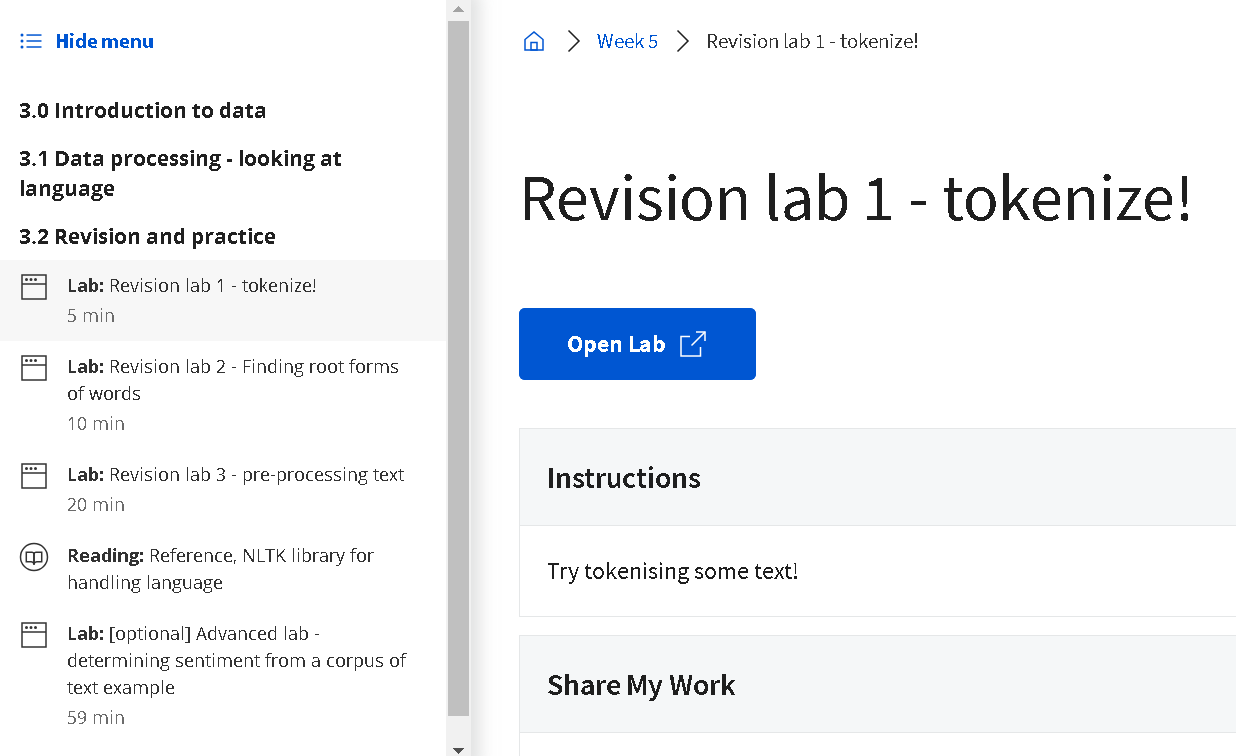

## Stopwords
[STOPWORD](stopword.ipynb)

Important Note: Ideally ,the code should be filtered not only non-alpha, but:
- Convert all words to lowercase.
- Remove non-alphabetic characters.
- Remove stop words.
- Remove punctuation.
- Remove numbers.
- Lemmatize words.
- Remove short words.
- Remove URLs.
- Remove special characters

The HSL color model stands for **Hue, Saturation, and Lightness**. It is a way to represent colors in a way that is more intuitive for humans to understand. Here's what each component means:

1. **Hue (0)**:
   - Hue represents the type of color and is measured in degrees on a color wheel. The value ranges from 0 to 360.
   - **0 degrees** corresponds to red. Other hues include 120 degrees for green and 240 degrees for blue.

2. **Saturation (100%)**:
   - Saturation measures the intensity or purity of the color. It ranges from 0% to 100%.
   - **100% saturation** means the color is fully saturated, with no gray, making it very vivid and pure.
   - **0% saturation** would be a shade of gray.

3. **Lightness (50%)**:
   - Lightness measures the brightness of the color. It ranges from 0% to 100%.
   - **50% lightness** is the midpoint, meaning the color is neither too dark nor too light.
   - **0% lightness** would be black, and **100% lightness** would be white.

So, **HSL(0, 100%, 50%)** represents a pure, vivid red color that is neither too dark nor too light. This is a common way to specify colors in web design and other digital applications because it allows for easy adjustments to the hue, saturation, and lightness to achieve the desired color effect.